# Structural Analysis

In [1]:
%load_ext autoreload
%autoreload 2

## Table of Contents

- [Mask density plots](#mask-density-plots): Plots for density of masks for attention + FF + all modules.
    - [(1) Attention + FF](#1-attention--ff)
    - [(2) All Modules](#2-all-modules) 


- [Venn diagrams for KG Overlap](#venn-diagrams-for-kg-overlap)
- [Venn diagrams for seed Overlap](#venn-diagrams-for-seed-overlap)

- [Jaccard sim of diff seeds same KG per module](#jaccard-sim-of-diff-seeds-same-kg-per-module)
- [Jaccard sim of diff KGs same seed per module](#jaccard-sim-of-diff-kgs-same-seed-per-module)

- [Removing and adding parameters to the remaining GPT2-small model](#removing-and-adding-parameters-to-the-remaining-gpt2-small-model)



## Mask density plots

### (1) Attention + FF

In [2]:
import os
from utils import set_seed, parse_json_to_dict
from vis import visualize_head_density, visualize_qkv_density, visualize_dense_density, get_model_and_config, visualize_all_layers_density_multi_model
import pandas as pd

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Synset('statement.n.01') 1318 26200.0
Synset('statement.n.01') 84 39400.0
Synset('location.n.01') 1318 39800.0
Synset('statement.n.01') 735 36400.0
Synset('building.n.01') 84 40000.0
Synset('building.n.01') 735 7400.0
Synset('location.n.01') 735 17800.0
Synset('building.n.01') 1318 40000.0
Synset('change.n.01') 1318 7800.0
Synset('change.n.01') 84 39600.0
Synset('communication.n.02') 84 24400.0
Synset('change.n.01') 735 8200.0
Synset('magnitude.n.01') 735 9200.0
Synset('representation.n.02') 84 8200.0
Synset('representation.n.02') 1318 33800.0
Synset('representation.n.02') 735 15800.0
Synset('communication.n.02') 735 37600.0
Synset('communication.n.02') 1318 39800.0
Synset('location.n.01') 84 30200.0
Synset('magnitude.n.01') 1318 6800.0
Synset('magnitude.n.01') 84 15800.0
{"Synset('statement.n.01')-1318": 26200.0, "Synset('statement.n.01')-84": 39400.0, "Synset('location.n.01')-1318": 39800.0, "Synset('statement.n.01')-735": 36400.0, "Synset('building.n.01')-84": 40000.0, "Synset('buil

<Figure size 640x480 with 0 Axes>

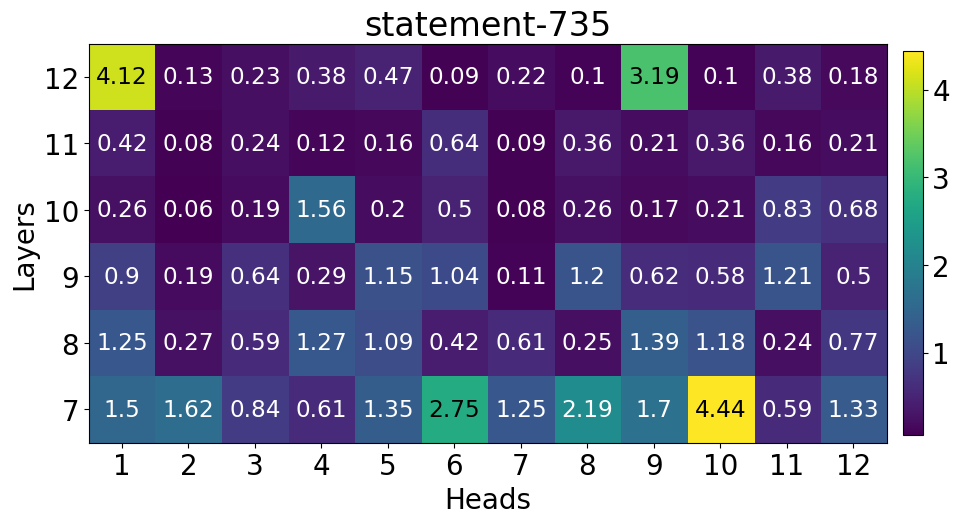

0.015514797531068325 0.01502312533557415 0.01984320767223835
0.0093994140625 0.00943840853869915 0.0044657387770712376
0.0082414411008358 0.00823974609375 0.004581027664244175
0.0050370958633720875 0.0047200522385537624 0.002804226242005825
0.0022905138321220875 0.0028008355293422937 0.0025278727989643812
0.001708984375 0.0030975341796875 0.01914299838244915


<Figure size 640x480 with 0 Axes>

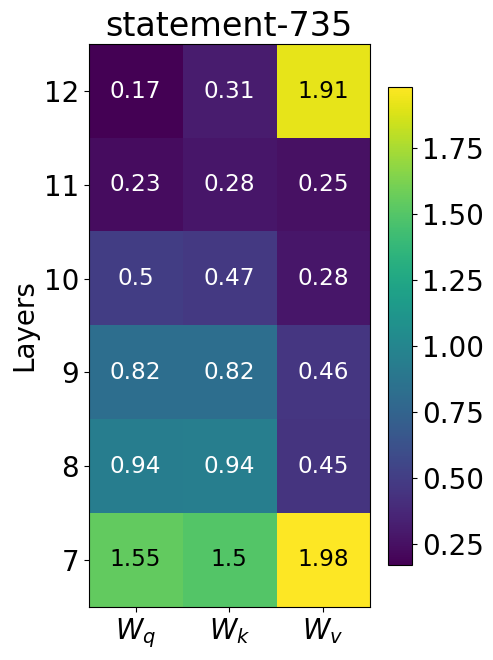

<Figure size 640x480 with 0 Axes>

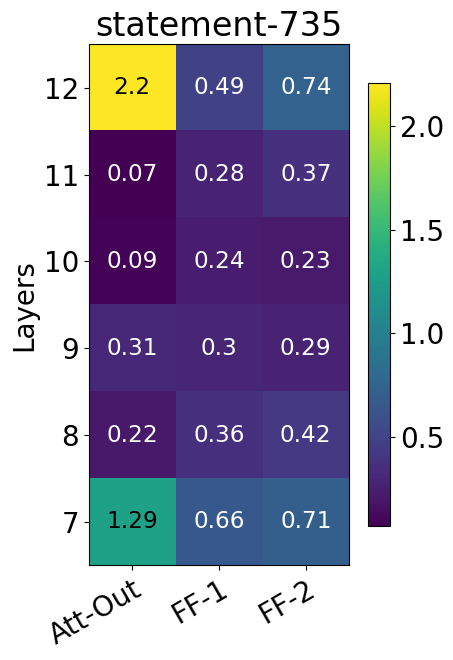

statement.n.01 735 building.n.01 84
statement.n.01 735 building.n.01 735
statement.n.01 735 location.n.01 735
statement.n.01 735 building.n.01 1318
statement.n.01 735 change.n.01 1318
statement.n.01 735 change.n.01 84
statement.n.01 735 communication.n.02 84
statement.n.01 735 change.n.01 735
statement.n.01 735 magnitude.n.01 735
statement.n.01 735 representation.n.02 84
statement.n.01 735 representation.n.02 1318
statement.n.01 735 representation.n.02 735
statement.n.01 735 communication.n.02 735
statement.n.01 735 communication.n.02 1318
statement.n.01 735 location.n.01 84
statement.n.01 735 magnitude.n.01 1318
statement.n.01 735 magnitude.n.01 84
Found the model and visualized.
statement.n.01 1318 statement.n.01 1318
--------------------------------------------------------------------------------
lm=gpt2-kg=statement.n.01-seed=1318-ablation=no_expression_targetkg-date=2025_10_08_11:40:23
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=statement.n.01-seed=1318-ablatio

<Figure size 640x480 with 0 Axes>

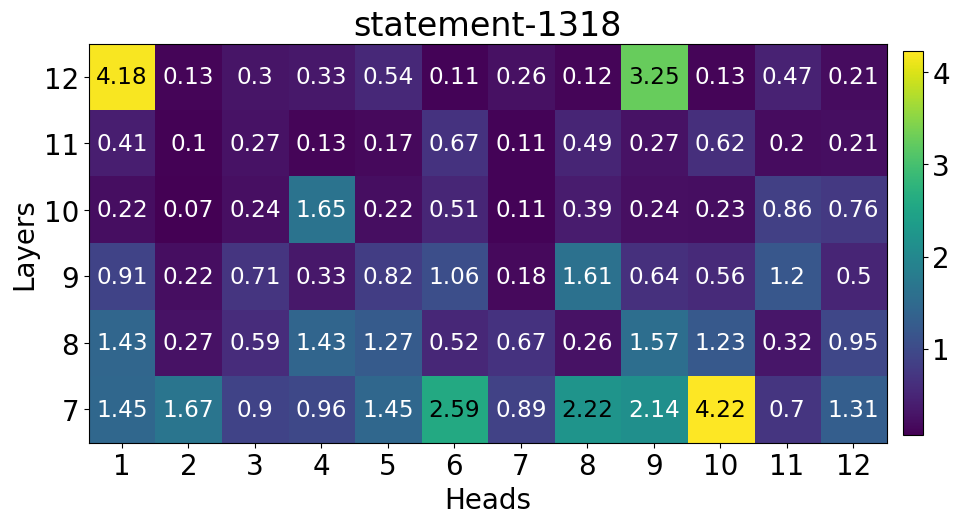

0.015080769546329975 0.0156097412109375 0.02059088833630085
0.0109117291867733 0.00994873046875 0.005420261062681675
0.00887213833630085 0.0081939697265625 0.004779391922056675
0.00531853549182415 0.0052964952774345875 0.003100925125181675
0.0027974445838481188 0.0034434001427143812 0.0029042561072856188
0.001922607421875 0.0036265056114643812 0.01949056051671505


<Figure size 640x480 with 0 Axes>

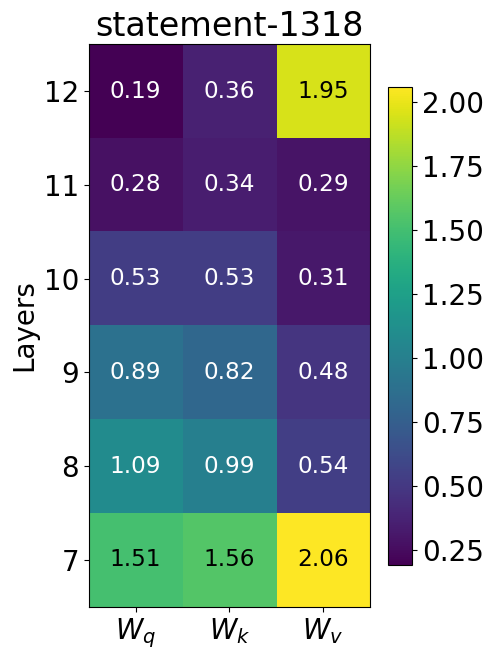

<Figure size 640x480 with 0 Axes>

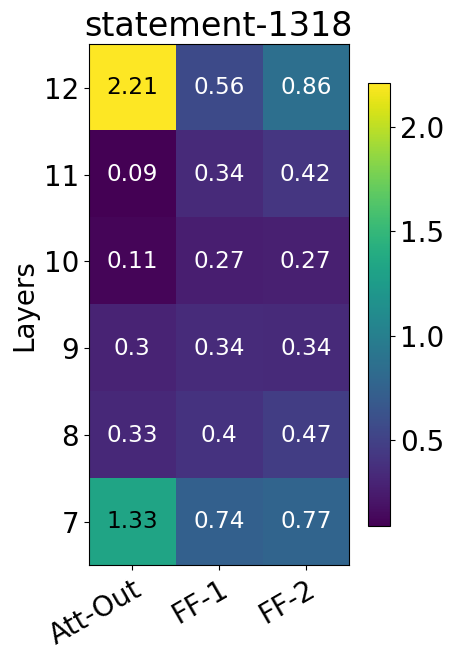

statement.n.01 1318 statement.n.01 84
statement.n.01 1318 location.n.01 1318
statement.n.01 1318 statement.n.01 735
statement.n.01 1318 building.n.01 84
statement.n.01 1318 building.n.01 735
statement.n.01 1318 location.n.01 735
statement.n.01 1318 building.n.01 1318
statement.n.01 1318 change.n.01 1318
statement.n.01 1318 change.n.01 84
statement.n.01 1318 communication.n.02 84
statement.n.01 1318 change.n.01 735
statement.n.01 1318 magnitude.n.01 735
statement.n.01 1318 representation.n.02 84
statement.n.01 1318 representation.n.02 1318
statement.n.01 1318 representation.n.02 735
statement.n.01 1318 communication.n.02 735
statement.n.01 1318 communication.n.02 1318
statement.n.01 1318 location.n.01 84
statement.n.01 1318 magnitude.n.01 1318
statement.n.01 1318 magnitude.n.01 84
Found the model and visualized.
statement.n.01 84 statement.n.01 1318
statement.n.01 84 statement.n.01 84
--------------------------------------------------------------------------------
lm=gpt2-kg=statement.n

<Figure size 640x480 with 0 Axes>

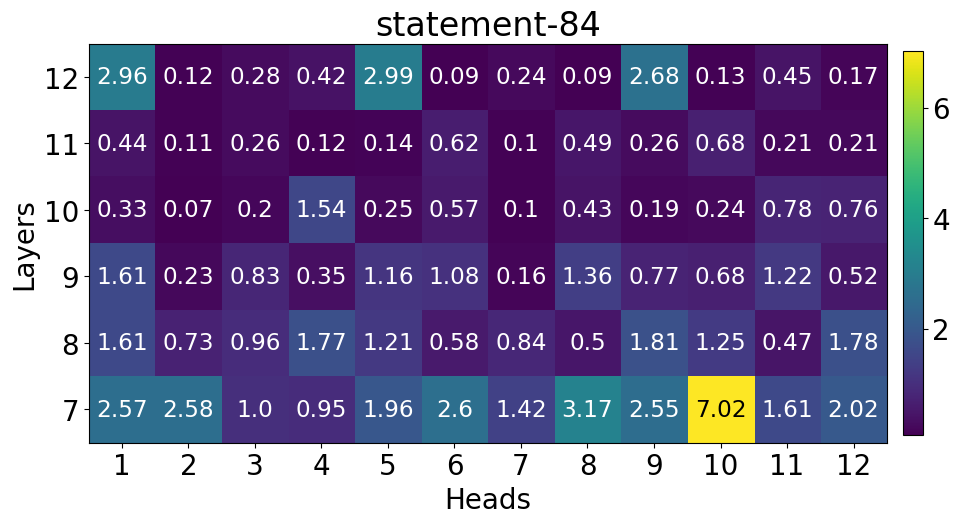

0.02397664450109005 0.0209164097905159 0.02873908169567585
0.013568454422056675 0.013049655593931675 0.00716315396130085
0.009521484375 0.0091535784304142 0.00623236782848835
0.0053117540664970875 0.00522698275744915 0.0031229655724018812
0.002994113601744175 0.0033043755684047937 0.0028177897911518812
0.0021311442833393812 0.0035959880333393812 0.020782470703125


<Figure size 640x480 with 0 Axes>

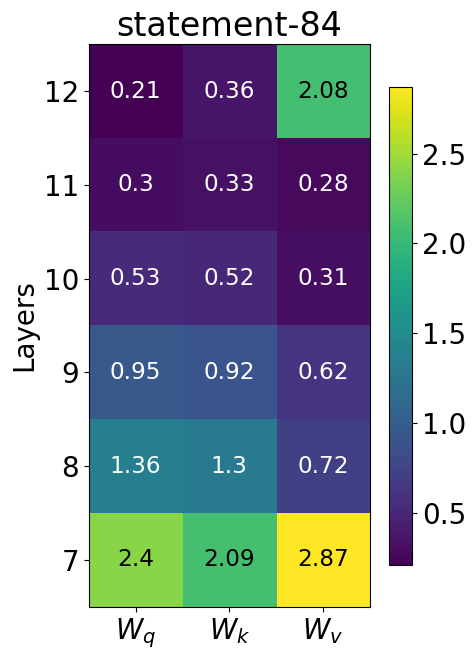

<Figure size 640x480 with 0 Axes>

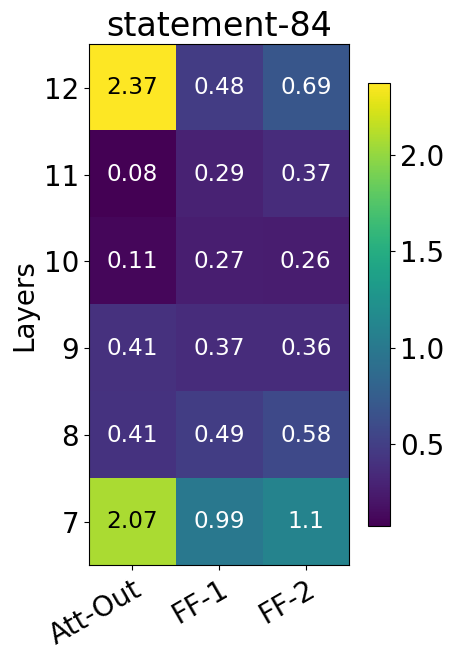

statement.n.01 84 location.n.01 1318
statement.n.01 84 statement.n.01 735
statement.n.01 84 building.n.01 84
statement.n.01 84 building.n.01 735
statement.n.01 84 location.n.01 735
statement.n.01 84 building.n.01 1318
statement.n.01 84 change.n.01 1318
statement.n.01 84 change.n.01 84
statement.n.01 84 communication.n.02 84
statement.n.01 84 change.n.01 735
statement.n.01 84 magnitude.n.01 735
statement.n.01 84 representation.n.02 84
statement.n.01 84 representation.n.02 1318
statement.n.01 84 representation.n.02 735
statement.n.01 84 communication.n.02 735
statement.n.01 84 communication.n.02 1318
statement.n.01 84 location.n.01 84
statement.n.01 84 magnitude.n.01 1318
statement.n.01 84 magnitude.n.01 84
Found the model and visualized.


In [3]:
set_seed(42)

project_name = "subnet_weights_wordnet" # "test_cleaning"
success_file = f"success_best_ckpnts-random=False.csv"
project_path = os.path.join("logs", project_name)
log_path = os.path.join(project_path, "logs")
best_df = pd.read_csv(os.path.join(project_path, success_file))

best_ckpnt_dict = {}
for index, row in best_df.iterrows():
    print(row['kg'], row['seed'], row['checkpoint step'])
    best_ckpnt_dict["{}-{}".format(row['kg'], row['seed'])] = row['checkpoint step']

print(best_ckpnt_dict)
print("="*80)

for kg in ['statement.n.01']: #['representation.n.02', 'location.n.01', 'communication.n.02']:
    for seed in [735, 1318, 84]:
        config_dict = {}
        cnt = 0
        for dirname in os.listdir(log_path):
            exper_path = os.path.join(log_path, dirname)
            config_path = os.path.join(exper_path, "config.json")
            config_dict = parse_json_to_dict(config_path)
            
            print(kg, seed, config_dict["targetkg_name"].split("'")[1], config_dict["seed"])
            
            if config_dict["targetkg_name"].split("'")[1] == kg and config_dict["seed"] == seed:
                print("-" * 80)
                print(dirname)
                if cnt > 1: 
                    print("Found more than 1 instance. Exiting...")
                step = str(int(best_ckpnt_dict["{}-{}".format(config_dict["targetkg_name"], config_dict["seed"])]))
                model, checkpoint_sparsity, config = get_model_and_config(exper_path, step)
                model.freeze_params(exclude_name_list=[], verbose=False)
                model.eval()
                os.makedirs(os.path.join("figs", "structure"), exist_ok=True)
                fig_base_path = os.path.join("figs", "structure", f"{kg}-{seed}")
                visualize_head_density(
                    model=model,
                    path=fig_base_path,
                    layers=12,
                    model_name=kg.replace(".n.02", "").replace(".n.01", "") + "-" + str(seed)
                )
                visualize_qkv_density(
                    model=model,
                    path=fig_base_path,
                    layers=12,
                    model_name=kg.replace(".n.02", "").replace(".n.01", "") + "-" + str(seed)
                )
                visualize_dense_density(
                    model=model, 
                    path=fig_base_path,
                    layers=12,
                    model_name=kg.replace(".n.02", "").replace(".n.01", "") + "-" + str(seed)
                )
                del model
                cnt += 1
        if cnt != 1:
            print("Did not find 1 instance. Exiting...")
        else:
            print("Found the model and visualized.")
             


### (2) All Modules

--------------------------------------------------------------------------------
lm=gpt2-kg=statement.n.01-seed=84-ablation=no_expression_targetkg-date=2025_10_08_11:40:23
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=statement.n.01-seed=84-ablation=no_expression_targetkg-date=2025_10_08_11:40:23/checkpoints/ckpt-step=39400-sparsity=0.99324
['ckpt', 'step=39400', 'sparsity=0.99324']
Checkpoint step: 39400
Checkpoint sparsity: 0.99324
--------------------------------------------------------------------------------
lm=gpt2-kg=statement.n.01-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:24
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=statement.n.01-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:24/checkpoints/ckpt-step=36400-sparsity=0.99466
['ckpt', 'step=36400', 'sparsity=0.99466']
Checkpoint step: 36400
Checkpoint sparsity: 0.99466


<Figure size 640x480 with 0 Axes>

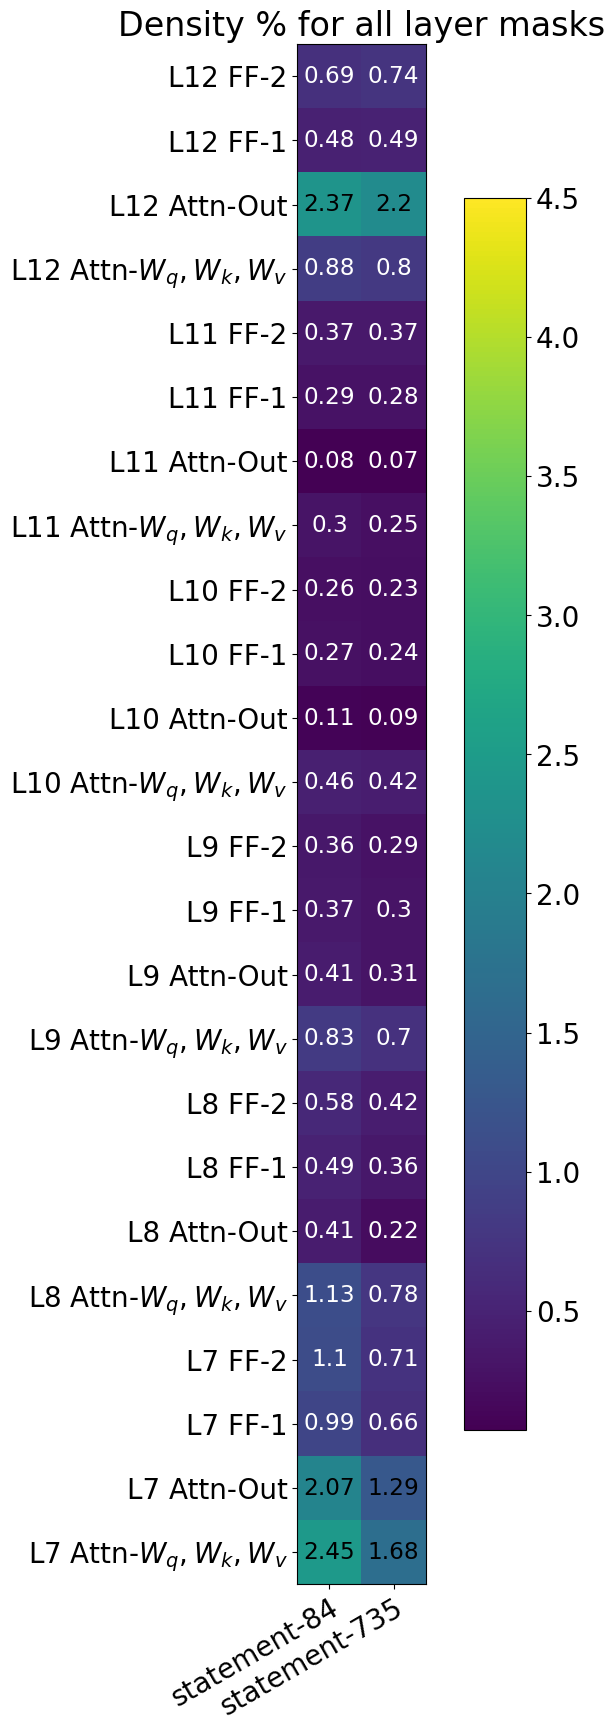

in_features
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 

<Figure size 640x480 with 0 Axes>

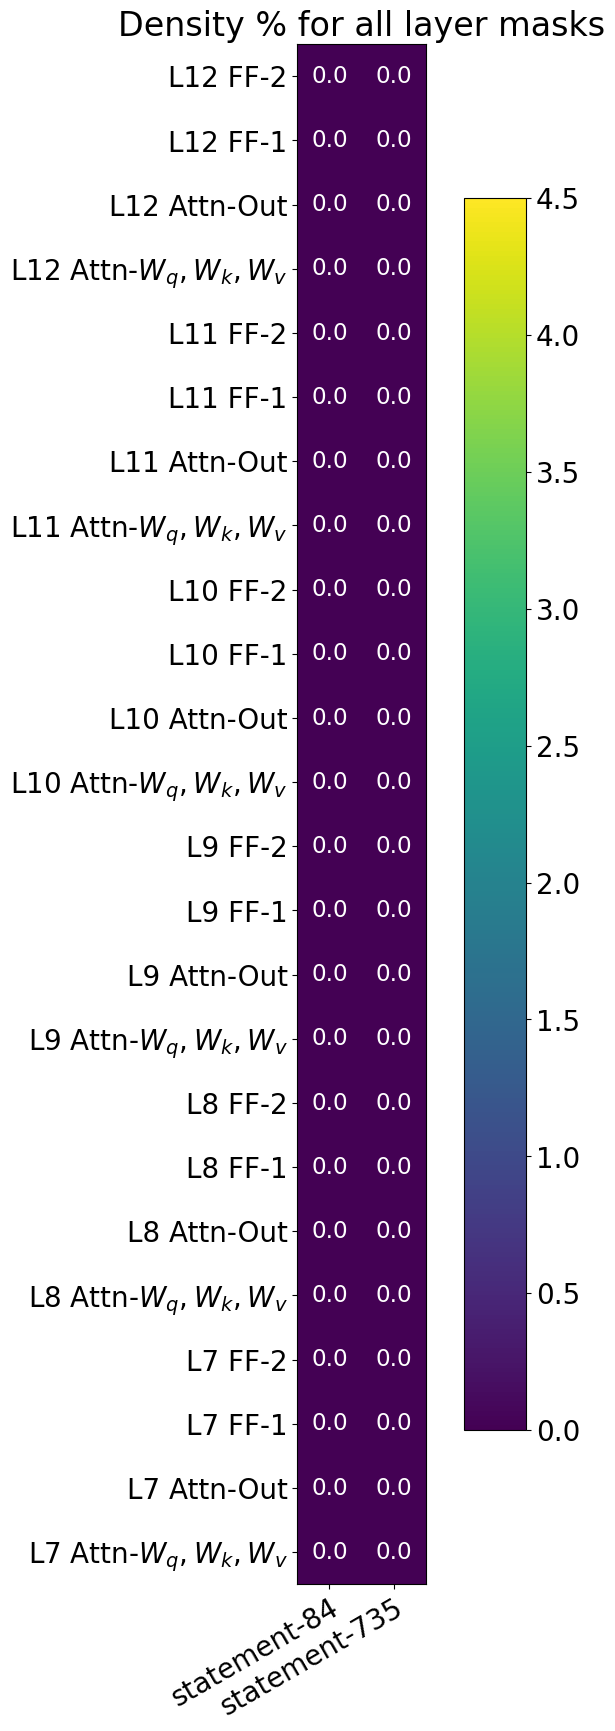

out_features
tensor([0., 0., 0.,  ..., 0., 0., 0.])
tensor([1., 1., 1.,  ..., 1., 1., 1.])
out_features
tensor([0., 0., 0.,  ..., 0., 0., 0.])
tensor([1., 1., 1.,  ..., 1., 1., 1.])


<Figure size 640x480 with 0 Axes>

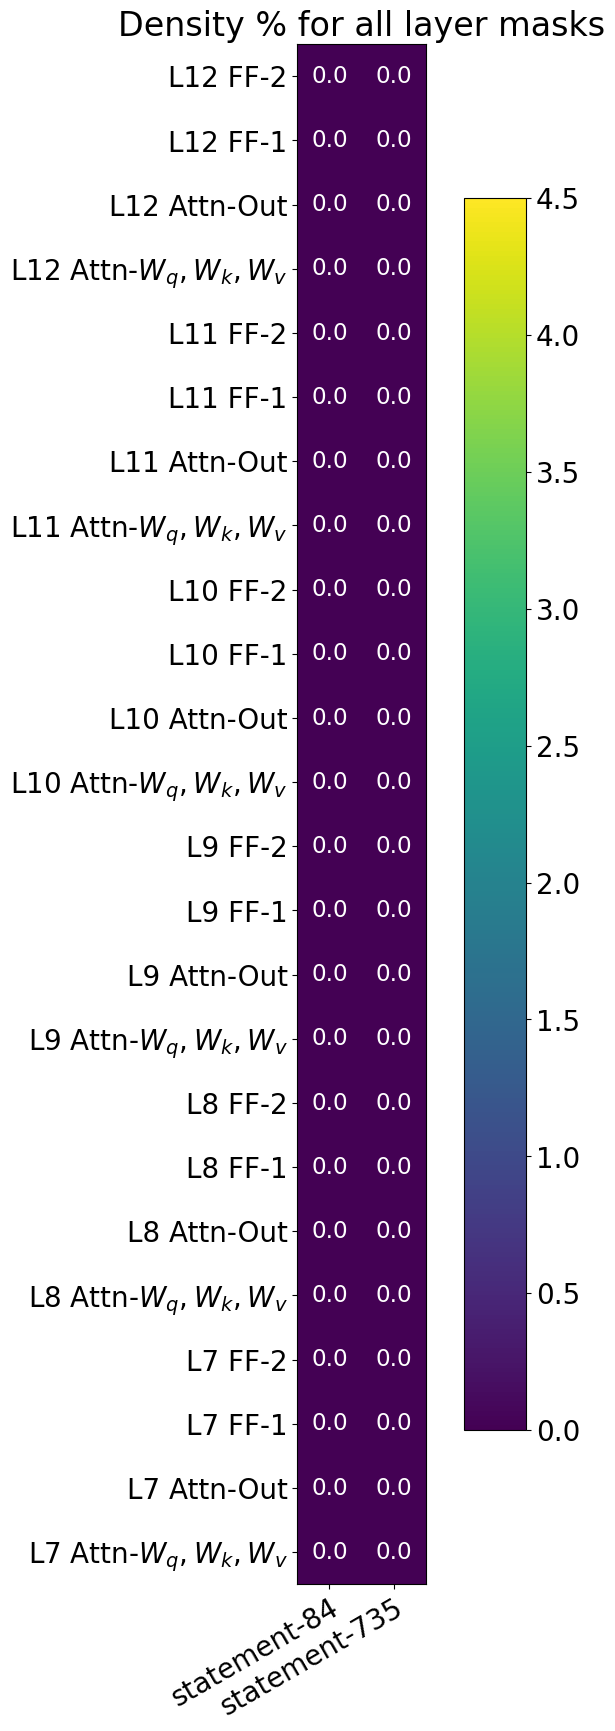

In [4]:
model_dict = {}
for kg in ['statement.n.01']: #['representation.n.02', 'location.n.01', 'communication.n.02']:
    for seed in [84, 735]: #[735, 1318, 84]:
        config_dict = {}
        cnt = 0
        for dirname in os.listdir(log_path):
            exper_path = os.path.join(log_path, dirname)
            config_path = os.path.join(exper_path, "config.json")
            config_dict = parse_json_to_dict(config_path)

            if config_dict["targetkg_name"].split("'")[1] == kg and config_dict["seed"] == seed:
                print("-" * 80)
                print(dirname)
                if cnt > 1: 
                    print("Found more than 1 instance. Exiting...")
                step = str(int(best_ckpnt_dict["{}-{}".format(config_dict["targetkg_name"],config_dict["seed"])]))
                model, checkpoint_sparsity, config = get_model_and_config(exper_path, step)
                model.freeze_params(exclude_name_list=[], verbose=False)
                model.eval()
                model_dict[f"{kg}-{seed}"] = model
                cnt += 1
        if cnt != 1:
            print("Did not find 1 instance. Exiting...")
                
visualize_all_layers_density_multi_model(
    model_dict=model_dict, 
    path=os.path.join("figs", "structure"),
    neuron_specific=False
)
visualize_all_layers_density_multi_model(
    model_dict=model_dict, 
    path=os.path.join("figs", "structure"),
    neuron_specific=True,
    neuron_type="in_features"
)
visualize_all_layers_density_multi_model(
    model_dict=model_dict, 
    path=os.path.join("figs", "structure"),
    neuron_specific=True,
    neuron_type="out_features"
)

## Venn diagrams for KG overlap

In [5]:
from know_subnet.lm.gpt2 import GPT2LM
from vis import calculate_tensor_subsets, plot_venn3_overlap

set_seed(42)

kg_list = ["representation.n.02", "location.n.01", "communication.n.02"]
seed_list = [735, 1318, 84]

os.makedirs(os.path.join("figs", "structure"), exist_ok=True)
instance = GPT2LM(use_dropout=False, lm_name="gpt2")
instance.eval()

for seed in seed_list:
    kg_masks = {}
    for kg in kg_list:
        cnt = 0
        for dirname in os.listdir(log_path):
            exper_path = os.path.join(log_path, dirname)
            config_path = os.path.join(exper_path, "config.json")
            config_dict = parse_json_to_dict(config_path)
            if config_dict["targetkg_name"].split("'")[1] == kg and config_dict["seed"] == seed:
                if cnt > 1:
                    print("Found more than 1 instance. Exiting...")
                step = str(int(best_ckpnt_dict["{}-{}".format(config_dict["targetkg_name"], config_dict["seed"])]))
                model, checkpoint_sparsity, config = get_model_and_config(exper_path, step)
                model.freeze_params(exclude_name_list=[], verbose=False)
                model.eval()
                masks = instance.get_combined_masks([model])
                kg_masks[kg] = masks
                cnt += 1
        if cnt != 1:
            print("Did not find 1 instance. Exiting...")
            continue

    if len(kg_masks) != len(kg_list):
        print(f"Skipping seed {seed} due to missing models.")
        continue

    subset_count = {"100": 0, "010": 0, "110": 0, "001": 0, "101": 0, "011": 0, "111": 0}
    param_loop = list(kg_masks[kg_list[0]].keys())
    for param_name in param_loop:
        mask1 = kg_masks[kg_list[0]][param_name]
        mask2 = kg_masks[kg_list[1]][param_name]
        mask3 = kg_masks[kg_list[2]][param_name]
        param_count = calculate_tensor_subsets(mask1, mask2, mask3)
        for key in subset_count.keys():
            subset_count[key] += param_count[key]

    plot_venn3_overlap(
        subset_count,
        labels=kg_list,
        title=f"Parameter overlap for different KGs and the same seed {seed}",
        save_path=os.path.join("figs", "structure"),
        filename=f"venn_kg_seed_{seed}.pdf",
    )


Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=15800-sparsity=0.99275
['ckpt', 'step=15800', 'sparsity=0.99275']
Checkpoint step: 15800
Checkpoint sparsity: 0.99275
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=location.n.01-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:25/checkpoints/ckpt-step=17800-sparsity=0.98969
['ckpt', 'step=17800', 'sparsity=0.98969']
Checkpoint step: 17800
Checkpoint sparsity: 0.98969
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=communication.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:32/checkpoints/ckpt-step=37600-sparsity=0.99488
['ckpt', 'step=37600', 'sparsity=0.99488']
Checkpoint step: 37600
Checkpoint sparsity: 0.99488
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=1318-ablation=no_expression_targetkg-date=2025_1

## Venn diagrams for seed overlap

In [6]:
from know_subnet.lm.gpt2 import GPT2LM
from vis import calculate_tensor_subsets, plot_venn3_overlap

set_seed(42)

kg_list = ["representation.n.02", "location.n.01", "communication.n.02"]
seed_list = [735, 1318, 84]

os.makedirs(os.path.join("figs", "structure"), exist_ok=True)
instance = GPT2LM(use_dropout=False, lm_name="gpt2")
instance.eval()

for kg in kg_list:
    seed_masks = {}
    for seed in seed_list:
        cnt = 0
        for dirname in os.listdir(log_path):
            exper_path = os.path.join(log_path, dirname)
            config_path = os.path.join(exper_path, "config.json")
            config_dict = parse_json_to_dict(config_path)
            if config_dict["targetkg_name"].split("'")[1] == kg and config_dict["seed"] == seed:
                if cnt > 1:
                    print("Found more than 1 instance. Exiting...")
                step = str(int(best_ckpnt_dict["{}-{}".format(config_dict["targetkg_name"], config_dict["seed"])]))
                model, checkpoint_sparsity, config = get_model_and_config(exper_path, step)
                model.freeze_params(exclude_name_list=[], verbose=False)
                model.eval()
                masks = instance.get_combined_masks([model])
                seed_masks[seed] = masks
                cnt += 1
        if cnt != 1:
            print("Did not find 1 instance. Exiting...")
            continue

    if len(seed_masks) != len(seed_list):
        print(f"Skipping KG {kg} due to missing models.")
        continue

    subset_count = {"100": 0, "010": 0, "110": 0, "001": 0, "101": 0, "011": 0, "111": 0}
    param_loop = list(seed_masks[seed_list[0]].keys())
    for param_name in param_loop:
        mask1 = seed_masks[seed_list[0]][param_name]
        mask2 = seed_masks[seed_list[1]][param_name]
        mask3 = seed_masks[seed_list[2]][param_name]
        param_count = calculate_tensor_subsets(mask1, mask2, mask3)
        for key in subset_count.keys():
            subset_count[key] += param_count[key]

    plot_venn3_overlap(
        subset_count,
        labels=[f"seed-{s}" for s in seed_list],
        title=f"Parameter overlap for different seeds and same KG {kg}",
        save_path=os.path.join("figs", "structure"),
        filename=f"venn_seed_{kg}.pdf",
    )


Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=15800-sparsity=0.99275
['ckpt', 'step=15800', 'sparsity=0.99275']
Checkpoint step: 15800
Checkpoint sparsity: 0.99275
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=1318-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=33800-sparsity=0.99446
['ckpt', 'step=33800', 'sparsity=0.99446']
Checkpoint step: 33800
Checkpoint sparsity: 0.99446
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=84-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=8200-sparsity=0.97842
['ckpt', 'step=8200', 'sparsity=0.97842']
Checkpoint step: 8200
Checkpoint sparsity: 0.97842
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=location.n.01-seed=735-ablation=no_expression_targetkg-date=2025_10_0

## Jaccard sim of diff seeds same KG per module

In [7]:
from know_subnet.lm.gpt2 import GPT2LM
from vis import jaccard_index_for_three, plot_jaccard_heatmap

set_seed(42)

kg_list = ["representation.n.02", "location.n.01", "communication.n.02"]
seed_list = [735, 1318, 84]

os.makedirs(os.path.join("figs", "structure"), exist_ok=True)
instance = GPT2LM(use_dropout=False, lm_name="gpt2")
instance.eval()

KG_sim_dict = {kg: {} for kg in kg_list}
for kg in kg_list:
    mask_list = []
    for seed in seed_list:
        cnt = 0
        for dirname in os.listdir(log_path):
            exper_path = os.path.join(log_path, dirname)
            config_path = os.path.join(exper_path, "config.json")
            config_dict = parse_json_to_dict(config_path)
            if config_dict["targetkg_name"].split("'")[1] == kg and config_dict["seed"] == seed:
                if cnt > 1:
                    print("Found more than 1 instance. Exiting...")
                step = str(int(best_ckpnt_dict["{}-{}".format(config_dict["targetkg_name"], config_dict["seed"])]))
                model, checkpoint_sparsity, config = get_model_and_config(exper_path, step)
                model.freeze_params(exclude_name_list=[], verbose=False)
                model.eval()
                masks = instance.get_combined_masks([model])
                mask_list.append(masks)
                cnt += 1
        if cnt != 1:
            print("Did not find 1 instance. Exiting...")
            break

    if len(mask_list) != len(seed_list):
        print(f"Skipping KG {kg} due to missing models.")
        continue

    for module_name in mask_list[0].keys():
        KG_sim_dict[kg][module_name] = jaccard_index_for_three(
            mask_list[0][module_name],
            mask_list[1][module_name],
            mask_list[2][module_name],
        )

plot_jaccard_heatmap(
    KG_sim_dict,
    "Jaccard similarity",
    os.path.join("figs", "structure"),
    "jaccard_seed_heatmap.pdf",
    "of different seeds for the same KG per module",
    column_formatter=lambda x: x.replace(".n.02", "").replace(".n.01", ""),
    x_rotation=45,
)


Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=15800-sparsity=0.99275
['ckpt', 'step=15800', 'sparsity=0.99275']
Checkpoint step: 15800
Checkpoint sparsity: 0.99275
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=1318-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=33800-sparsity=0.99446
['ckpt', 'step=33800', 'sparsity=0.99446']
Checkpoint step: 33800
Checkpoint sparsity: 0.99446
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=84-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=8200-sparsity=0.97842
['ckpt', 'step=8200', 'sparsity=0.97842']
Checkpoint step: 8200
Checkpoint sparsity: 0.97842
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=location.n.01-seed=735-ablation=no_expression_targetkg-date=2025_10_0

<Figure size 640x480 with 0 Axes>

## Jaccard sim of diff KGs same seed per module

In [8]:
from know_subnet.lm.gpt2 import GPT2LM
from vis import jaccard_index_for_three, plot_jaccard_heatmap

set_seed(42)

kg_list = ["representation.n.02", "location.n.01", "communication.n.02"]
seed_list = [735, 1318, 84]

os.makedirs(os.path.join("figs", "structure"), exist_ok=True)
instance = GPT2LM(use_dropout=False, lm_name="gpt2")
instance.eval()

KG_sim_dict = {seed: {} for seed in seed_list}
for seed in seed_list:
    mask_list = []
    for kg in kg_list:
        cnt = 0
        for dirname in os.listdir(log_path):
            exper_path = os.path.join(log_path, dirname)
            config_path = os.path.join(exper_path, "config.json")
            config_dict = parse_json_to_dict(config_path)
            if config_dict["targetkg_name"].split("'")[1] == kg and config_dict["seed"] == seed:
                if cnt > 1:
                    print("Found more than 1 instance. Exiting...")
                step = str(int(best_ckpnt_dict["{}-{}".format(config_dict["targetkg_name"], config_dict["seed"])]))
                model, checkpoint_sparsity, config = get_model_and_config(exper_path, step)
                model.freeze_params(exclude_name_list=[], verbose=False)
                model.eval()
                masks = instance.get_combined_masks([model])
                mask_list.append(masks)
                cnt += 1
        if cnt != 1:
            print("Did not find 1 instance. Exiting...")
            break

    if len(mask_list) != len(kg_list):
        print(f"Skipping seed {seed} due to missing models.")
        continue

    for module_name in mask_list[0].keys():
        KG_sim_dict[seed][module_name] = jaccard_index_for_three(
            mask_list[0][module_name],
            mask_list[1][module_name],
            mask_list[2][module_name],
        )

plot_jaccard_heatmap(
    KG_sim_dict,
    "Jaccard similarity",
    os.path.join("figs", "structure"),
    "jaccard_kg_heatmap.pdf",
    "of different KGs for the same seed per module",
    x_rotation=30,
)


Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=15800-sparsity=0.99275
['ckpt', 'step=15800', 'sparsity=0.99275']
Checkpoint step: 15800
Checkpoint sparsity: 0.99275
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=location.n.01-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:25/checkpoints/ckpt-step=17800-sparsity=0.98969
['ckpt', 'step=17800', 'sparsity=0.98969']
Checkpoint step: 17800
Checkpoint sparsity: 0.98969
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=communication.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:32/checkpoints/ckpt-step=37600-sparsity=0.99488
['ckpt', 'step=37600', 'sparsity=0.99488']
Checkpoint step: 37600
Checkpoint sparsity: 0.99488
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=1318-ablation=no_expression_targetkg-date=2025_1

<Figure size 640x480 with 0 Axes>

## Removing and adding parameters to the remaining GPT2-small model

In [ ]:
# import copy
# from know_subnet.lm.gpt2 import GPT2LM

# set_seed(42)

# kg_list = ["representation.n.02", "location.n.01", "communication.n.02"]
# seed = 735

# combined_models = []
# config = None
# for kg in kg_list:
#     cnt = 0
#     for dirname in os.listdir(log_path):
#         exper_path = os.path.join(log_path, dirname)
#         config_path = os.path.join(exper_path, "config.json")
#         config_dict = parse_json_to_dict(config_path)
#         if config_dict["targetkg_name"].split("'")[1] == kg and config_dict["seed"] == seed:
#             if cnt > 1:
#                 print("Found more than 1 instance. Exiting...")
#             step = str(int(best_ckpnt_dict["{}-{}".format(config_dict["targetkg_name"], config_dict["seed"])]))
#             model, checkpoint_sparsity, config = get_model_and_config(exper_path, step)
#             model.freeze_params(exclude_name_list=[], verbose=False)
#             model.eval()
#             combined_models.append(model)
#             cnt += 1
#     if cnt != 1:
#         print("Did not find 1 instance. Exiting...")
#         break

# if len(combined_models) != len(kg_list):
#     print("Did not find all 3 models for composition. Exiting...")
# else:
#     base_model = GPT2LM(use_dropout=False, lm_name=config["lm"])
#     base_model.freeze_params(exclude_name_list=[], verbose=False)
#     base_model.eval()

#     unioned_masks = base_model.get_combined_masks(combined_models)

#     def mask_density(boolean_masks):
#         tot_mask_size = sum(mask.sum().item() for mask in boolean_masks.values())
#         tot_param_size = sum(mask.numel() for mask in boolean_masks.values())
#         return 1 - (tot_mask_size / tot_param_size)

#     current_density = mask_density(unioned_masks)
#     print("Base density after removal:", current_density)

#     target_add_density = min(1.0, current_density + 0.05)
#     add_model = GPT2LM(use_dropout=False, lm_name=config["lm"])
#     add_model.freeze_params(exclude_name_list=[], verbose=False)
#     add_model.eval()
#     added_masks = add_model.random_add_more(copy.deepcopy(unioned_masks), pct_goal=target_add_density)
#     print("Density after adding:", mask_density(added_masks))

#     target_remove_density = max(0.0, current_density - 0.05)
#     remove_model = GPT2LM(use_dropout=False, lm_name=config["lm"])
#     remove_model.freeze_params(exclude_name_list=[], verbose=False)
#     remove_model.eval()
#     removed_masks = remove_model.random_remove_more(copy.deepcopy(unioned_masks), pct_goal=target_remove_density)
#     print("Density after removing:", mask_density(removed_masks))


Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=representation.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:30/checkpoints/ckpt-step=15800-sparsity=0.99275
['ckpt', 'step=15800', 'sparsity=0.99275']
Checkpoint step: 15800
Checkpoint sparsity: 0.99275
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=location.n.01-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:25/checkpoints/ckpt-step=17800-sparsity=0.98969
['ckpt', 'step=17800', 'sparsity=0.98969']
Checkpoint step: 17800
Checkpoint sparsity: 0.98969
Loading model from: logs/subnet_weights_wordnet/logs/lm=gpt2-kg=communication.n.02-seed=735-ablation=no_expression_targetkg-date=2025_10_08_11:40:32/checkpoints/ckpt-step=37600-sparsity=0.99488
['ckpt', 'step=37600', 'sparsity=0.99488']
Checkpoint step: 37600
Checkpoint sparsity: 0.99488
Base density after removal: 0.9814143239715953
Density after adding: 1.0
Density after removing: 0.9314143098430869
